# Toxicity Classification and Fairness in Online Moderation

## 04 - Fairness analysis

This notebook is the main research and analysis component of our project. Now that we've trained both classifiers, we'll investigate how their performance differs and whether they exhibit potential demographic bias.

Objectives:
1. Load and verify test predictions from logistic regression and DistilBERT
2. Compare overall classification performance across both models
3. Identify demographic identity groups and analyze their toxicity distributions
4. Evaluate demographic fairness using subgroup false-positive and false-negative rates
5. Visualize and compare classification errors across demographic groups and models
6. Conduct counterfactual analysis by changing identity terms in otherwise identical comments
7. Examine representative false positives, false negatives, and model disagreements
8. Interpret findings, discuss limitations, and save results for the final report and interactive demo

### Import necessary packages - load prepared dataset

In [64]:
# imports and load data

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, average_precision_score, confusion_matrix, ConfusionMatrixDisplay
import joblib
import torch
from transformers import AutoTokenizer, AutoModelForSequenceClassification

#### Loading the test predictions

Load the saved test predictions from both classifiers and combine them into a single dataset for comparison. Verify that both models evaluated the same comments with identical ground-truth labels to ensure a valid comparison of classification performance and fairness.

In [10]:
# load saved model predictions
lr = pd.read_csv("../results/logistic_predictions.csv")
bert = pd.read_csv("../results/distilbert_test_predictions.csv")

print("Logistic regression predictions:", lr.shape)
print("DistilBERT predictions:", bert.shape)

print("Logistic regression columns:", lr.columns.tolist())
print("DistilBERT columns:", bert.columns.tolist())

Logistic regression predictions: (96862, 4)
DistilBERT predictions: (96862, 4)
Logistic regression columns: ['text', 'label', 'lr_probability', 'lr_prediction']
DistilBERT columns: ['text', 'label', 'distilbert_probability', 'distilbert_prediction']


In [14]:
# verify no duplicate texts or missing values
assert not lr["text"].duplicated().any()
assert not bert["text"].duplicated().any()
assert not lr[["text", "label"]].isna().any().any()
assert not bert[["text", "label"]].isna().any().any()

# combine model predictions using comment text
df = lr.merge(
    bert,
    on="text",
    suffixes=("_lr", "_bert"),
    validate="one_to_one"
)

# verify every comment matched and labels agree
assert len(df) == len(lr) == len(bert)
assert (df["label_lr"] == df["label_bert"]).all()

# create one shared ground-truth label
# we don't want to ever compare the two models' predictions against different comments
df["label"] = df["label_lr"]
df = df.drop(columns=["label_lr", "label_bert"])

print("Combined dataset:", df.shape)
print("All comments and labels match successfully.")

display(df.head())

Combined dataset: (96862, 6)
All comments and labels match successfully.


,text,lr_probability,lr_prediction,distilbert_probability,distilbert_prediction,label
0,[ Integrity means that you pay your debts.]\n\...,0.011675,0,0.001926,0,0
1,This is malfeasance by the Administrator and t...,0.024112,0,0.008311,0,0
2,@Rmiller101 - Spoken like a true elitist. But ...,0.100954,0,0.029269,0,0
3,"Paul: Thank you for your kind words. I do, in...",0.003677,0,0.019603,0,0
4,Sorry you missed high school. Eisenhower sent ...,0.005896,0,0.004353,0,0


In [16]:
# verify predictions and probabilities are valid
for model in ["lr", "distilbert"]:
    assert df[f"{model}_prediction"].isin([0, 1]).all()
    assert df[f"{model}_probability"].between(0, 1).all()

assert df["label"].isin([0, 1]).all()

print("Total comments:", len(df))
print("Toxic comments:", (df["label"] == 1).sum())
print("Non-toxic comments:", (df["label"] == 0).sum())
print("All prediction values verified.")

Total comments: 96862
Toxic comments: 7739
Non-toxic comments: 89123
All prediction values verified.


#### Compare overall performance

Compare logistic regression and DistilBERT using predictions on the same held-out test dataset. We calculate accuracy, precision, recall, F1, average precision (PR-AUC), false-positive rate (FPR), and false-negative rate (FNR) to assess each model's ability to identify toxic comments while minimizing incorrect classifications.

In [23]:
results = []

# get the corresponding probabilities
for name, prefix in [("Logistic Regression", "lr"), ("DistilBERT", "distilbert")]:
    preds = df[f"{prefix}_prediction"]
    probs = df[f"{prefix}_probability"]

    tn, fp, fn, tp = confusion_matrix(df["label"], preds, labels=[0, 1]).ravel()

    # build the full results list
    results.append({
        "Model": name,
        "Accuracy": accuracy_score(df["label"], preds),
        "Precision": precision_score(df["label"], preds),
        "Recall": recall_score(df["label"], preds),
        "F1": f1_score(df["label"], preds),
        "PR-AUC": average_precision_score(df["label"], probs),
        "FPR": fp / (fp + tn),
        "FNR": fn / (fn + tp)
    })

performance_df = pd.DataFrame(results)
display(performance_df.round(4))

,Model,Accuracy,Precision,Recall,F1,PR-AUC,FPR,FNR
0,Logistic Regression,0.9438,0.6466,0.6540,0.6503,0.7080,0.031,0.3460
1,DistilBERT,0.9475,0.6818,0.6427,0.6617,0.7291,0.026,0.3573


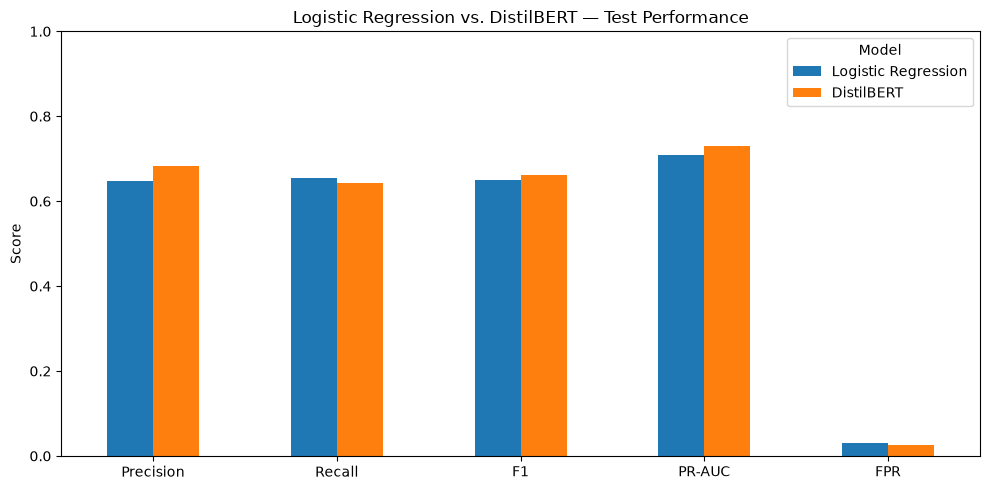

In [25]:
# plot key classification metrics for both models
metrics = ["Precision", "Recall", "F1", "PR-AUC", "FPR"]

performance_df.set_index("Model")[metrics].T.plot(
    kind="bar",
    figsize=(10, 5),
    rot=0
)

plt.title("Logistic Regression vs. DistilBERT — Test Performance")
plt.ylabel("Score")
plt.ylim(0, 1)
plt.legend(title="Model")
plt.tight_layout()
plt.show()

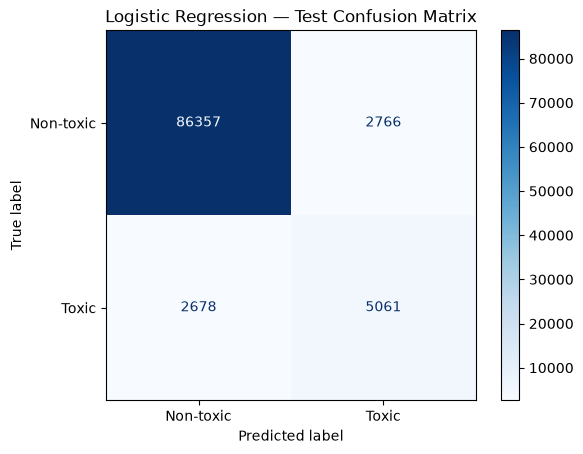

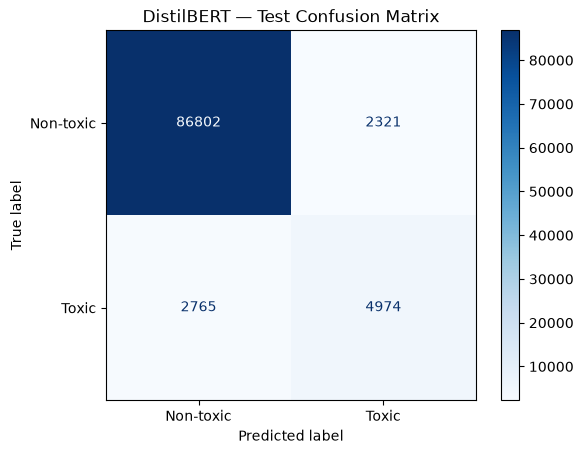

In [31]:
for name, prefix in [("Logistic Regression", "lr"), ("DistilBERT", "distilbert")]:
    cm = confusion_matrix(df["label"], df[f"{prefix}_prediction"], labels=[0, 1])

    disp = ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=["Non-toxic", "Toxic"]
    )

    disp.plot(cmap="Blues", values_format="d")
    plt.title(f"{name} — Test Confusion Matrix")
    plt.show()

#### Identify identity groups and toxicity distribution

Identify comments mentioning demographic identities using regular expressions. We examine 15 groups across race/ethnicity, religion, gender, and sexual orientation. For each group, calculate the number of comments, number of toxic comments, and proportion labeled toxic in the test dataset. Identity mentions are not mutually exclusive, and mentioning an identity does not necessarily indicate the commenter's own identity. These groupings are approximate and will be used to investigate differences in classification errors across identity-related comments.

In [36]:
# define demographic groups and associated keywords
identity_patterns = {
    # race and ethnicity
    "Black": r"\b(?:black|african american|african americans)\b",
    "White": r"\b(?:white|caucasian|caucasians)\b",
    "Asian": r"\b(?:asian|asians)\b",
    "Hispanic/Latino": r"\b(?:hispanic|hispanics|latino|latina|latinos|latinas)\b",

    # religion
    "Muslim": r"\b(?:muslim|muslims|islam|islamic)\b",
    "Christian": r"\b(?:christian|christians|christianity)\b",
    "Jewish": r"\b(?:jewish|jews|judaism)\b",
    "Hindu": r"\b(?:hindu|hindus|hinduism)\b",
    "Buddhist": r"\b(?:buddhist|buddhists|buddhism)\b",
    "Atheist": r"\b(?:atheist|atheists|atheism)\b",

    # gender
    "Male": r"\b(?:man|men|male|males)\b",
    "Female": r"\b(?:woman|women|female|females)\b",
    "Transgender": r"\b(?:transgender|transsexual|transwoman|transman)\b",

    # sexual orientation
    "Gay/Lesbian": r"\b(?:gay|gays|lesbian|lesbians|homosexual|homosexuals)\b",
    "Bisexual": r"\b(?:bisexual|bisexuals)\b"
}

print("Number of demographic groups:", len(identity_patterns))

Number of demographic groups: 15


In [38]:
# identify identity mentions in each comment
for group, pattern in identity_patterns.items():
    df[group] = df["text"].str.contains(
        pattern,
        case=False,
        regex=True,
        na=False
    )

# verify group identification
print("Total comments:", len(df))
print("Comments mentioning at least one identity:",
      df[list(identity_patterns)].any(axis=1).sum())

display(df[["text", "label"] + list(identity_patterns)[:4]].head())

Total comments: 96862
Comments mentioning at least one identity: 9759


,text,label,Black,White,Asian,Hispanic/Latino
0,[ Integrity means that you pay your debts.]\n\...,0,False,False,False,False
1,This is malfeasance by the Administrator and t...,0,False,False,False,False
2,@Rmiller101 - Spoken like a true elitist. But ...,0,False,False,False,False
3,"Paul: Thank you for your kind words. I do, in...",0,False,False,False,False
4,Sorry you missed high school. Eisenhower sent ...,0,False,False,False,False


In [40]:
# calculate subgroup sizes and annotated toxicity rates
group_results = []

for group in identity_patterns:
    subset = df[df[group]]

    group_results.append({
        "Group": group,
        "Comments": len(subset),
        "Toxic Comments": int(subset["label"].sum()),
        "Toxicity Rate": subset["label"].mean()
    })

group_df = pd.DataFrame(group_results).sort_values(
    "Comments", ascending=False
)

display(group_df.round(4))

print("Overall toxicity rate:", round(df["label"].mean(), 4))

,Group,Comments,Toxic Comments,Toxicity Rate
10,Male,3548,483,0.1361
11,Female,2526,330,0.1306
1,White,1928,422,0.2189
4,Muslim,1183,250,0.2113
0,Black,1071,235,0.2194
5,Christian,891,134,0.1504
13,Gay/Lesbian,468,135,0.2885
6,Jewish,384,56,0.1458
9,Atheist,149,9,0.0604
2,Asian,130,12,0.0923


Overall toxicity rate: 0.0799


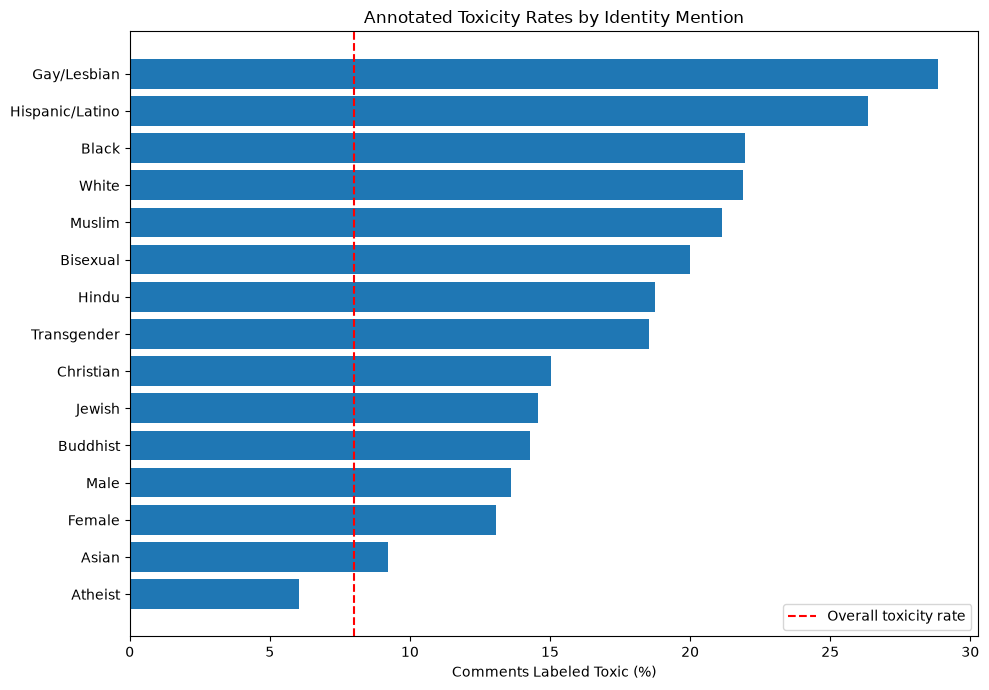

In [42]:
# visualize annotated toxicity rates by demographic group
plot_df = group_df.sort_values("Toxicity Rate")

plt.figure(figsize=(10, 7))
plt.barh(plot_df["Group"], plot_df["Toxicity Rate"] * 100)

plt.axvline(
    df["label"].mean() * 100,
    color="red",
    linestyle="--",
    label="Overall toxicity rate"
)

plt.xlabel("Comments Labeled Toxic (%)")
plt.title("Annotated Toxicity Rates by Identity Mention")
plt.legend()
plt.tight_layout()
plt.show()

#### Quantitative fairness

Evaluate whether classification errors differ across the 15 demographic identity groups identified in Step 3. For each group, calculate false-positive rates (FPR) and false-negative rates (FNR) for both logistic regression and DistilBERT, and compare them against overall model performance. We also report the number of non-toxic and toxic comments in each group, since small sample sizes can make error rates unreliable. These comparisons identify potential disparities in classification errors but do not necessarily establish discriminatory bias

In [45]:
# calculate FPR and FNR for each demographic group and model
fairness_results = []

for group in identity_patterns:
    subset = df[df[group]]

    for name, prefix in [("Logistic Regression", "lr"), ("DistilBERT", "distilbert")]:
        tn, fp, fn, tp = confusion_matrix(
            subset["label"],
            subset[f"{prefix}_prediction"],
            labels=[0, 1]
        ).ravel()

        fairness_results.append({
            "Group": group,
            "Model": name,
            "Comments": len(subset),
            "Non-toxic": tn + fp,
            "Toxic": tp + fn,
            "FPR": fp / (fp + tn) if (fp + tn) > 0 else np.nan,
            "FNR": fn / (fn + tp) if (fn + tp) > 0 else np.nan
        })

fairness_df = pd.DataFrame(fairness_results)

display(fairness_df.round(4))

,Group,Model,Comments,Non-toxic,Toxic,FPR,FNR
0,Black,Logistic Regression,1071,836,235,0.1830,0.2511
1,Black,DistilBERT,1071,836,235,0.1758,0.2936
2,White,Logistic Regression,1928,1506,422,0.1740,0.2773
3,White,DistilBERT,1928,1506,422,0.1408,0.3507
4,Asian,Logistic Regression,130,118,12,0.0424,0.0833
5,Asian,DistilBERT,130,118,12,0.0339,0.2500
6,Hispanic/Latino,Logistic Regression,129,95,34,0.1053,0.2941
7,Hispanic/Latino,DistilBERT,129,95,34,0.0842,0.3824
8,Muslim,Logistic Regression,1183,933,250,0.1618,0.3840
9,Muslim,DistilBERT,1183,933,250,0.0750,0.5040


In [47]:
# compare false-positive rates between models
fpr_comparison = fairness_df.pivot(
    index="Group",
    columns="Model",
    values="FPR"
)

# include the number of non-toxic comments per group
fpr_comparison["Non-toxic Comments"] = (
    fairness_df[fairness_df["Model"] == "Logistic Regression"]
    .set_index("Group")["Non-toxic"]
)

fpr_comparison["Difference (BERT - LR)"] = (
    fpr_comparison["DistilBERT"] -
    fpr_comparison["Logistic Regression"]
)

fpr_comparison = fpr_comparison.sort_values(
    "Difference (BERT - LR)"
)

display(fpr_comparison.round(4))

Model,DistilBERT,Logistic Regression,Non-toxic Comments,Difference (BERT - LR)
Group,,,,
Muslim,0.0750,0.1618,933,-0.0868
Jewish,0.0640,0.1250,328,-0.0610
Buddhist,0.0417,0.0833,24,-0.0417
Hindu,0.0000,0.0385,26,-0.0385
Christian,0.0476,0.0845,757,-0.0370
Male,0.0555,0.0897,3065,-0.0343
Female,0.0474,0.0811,2196,-0.0337
White,0.1408,0.1740,1506,-0.0332
Atheist,0.0286,0.0571,140,-0.0286


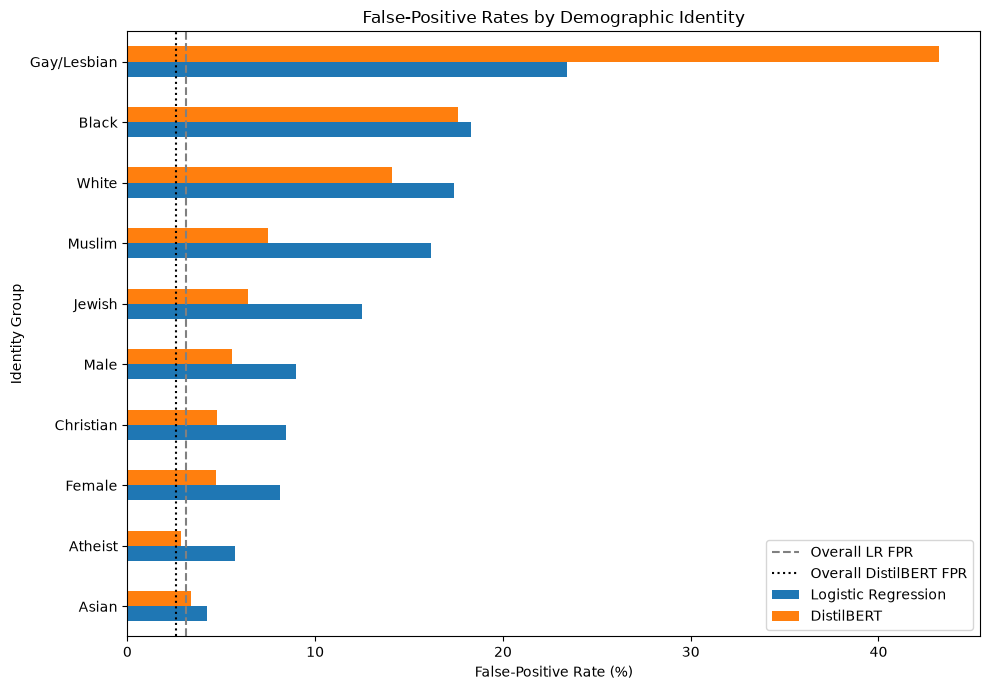

In [49]:
# focus on groups with at least 100 non-toxic examples
plot_df = fpr_comparison[
    fpr_comparison["Non-toxic Comments"] >= 100
].sort_values("Logistic Regression")

ax = (plot_df[["Logistic Regression", "DistilBERT"]] * 100).plot(
    kind="barh",
    figsize=(10, 7)
)

plt.axvline(
    performance_df.loc[0, "FPR"] * 100,
    color="gray",
    linestyle="--",
    label="Overall LR FPR"
)

plt.axvline(
    performance_df.loc[1, "FPR"] * 100,
    color="black",
    linestyle=":",
    label="Overall DistilBERT FPR"
)

plt.xlabel("False-Positive Rate (%)")
plt.ylabel("Identity Group")
plt.title("False-Positive Rates by Demographic Identity")
plt.legend()
plt.tight_layout()
plt.show()

In [51]:
# compare false-negative rates between models
fnr_comparison = fairness_df.pivot(
    index="Group",
    columns="Model",
    values="FNR"
)

fnr_comparison["Toxic Comments"] = (
    fairness_df[fairness_df["Model"] == "Logistic Regression"]
    .set_index("Group")["Toxic"]
)

fnr_comparison["Difference (BERT - LR)"] = (
    fnr_comparison["DistilBERT"] -
    fnr_comparison["Logistic Regression"]
)

fnr_comparison = fnr_comparison.sort_values(
    "Difference (BERT - LR)"
)

display(fnr_comparison.round(4))

Model,DistilBERT,Logistic Regression,Toxic Comments,Difference (BERT - LR)
Group,,,,
Gay/Lesbian,0.1630,0.4074,135,-0.2444
Atheist,0.4444,0.4444,9,0.0000
Black,0.2936,0.2511,235,0.0426
Male,0.3685,0.3106,483,0.0580
Transgender,0.3333,0.2667,15,0.0667
Female,0.4091,0.3424,330,0.0667
White,0.3507,0.2773,422,0.0735
Hispanic/Latino,0.3824,0.2941,34,0.0882
Muslim,0.5040,0.3840,250,0.1200


In [53]:
# verify subgroup counts and error rates
assert (fairness_df["Non-toxic"] + fairness_df["Toxic"]
        == fairness_df["Comments"]).all()

assert fairness_df["FPR"].dropna().between(0, 1).all()
assert fairness_df["FNR"].dropna().between(0, 1).all()

assert len(fairness_df) == len(identity_patterns) * 2

print("Fairness analysis verified.")
print("Groups evaluated:", len(identity_patterns))
print("Model-group comparisons:", len(fairness_df))

Fairness analysis verified.
Groups evaluated: 15
Model-group comparisons: 30


#### Counterfactual analysis

Investigate how demographic identity terms affect toxicity predictions by creating pairs of comments that differ only in the identity mentioned. We test both non-toxic and toxic sentence templates, substituting different identity terms while holding the surrounding language constant. We then compare how logistic regression and DistilBERT respond to these substitutions, examining whether certain identities consistently receive higher predicted toxicity scores. These tests measure sensitivity to identity terms but do not independently establish discriminatory bias

In [66]:
# load logistic regression model, vectorizer, and threshold
lr_model, lr_vectorizer, lr_threshold = joblib.load(
    "../models/logistic_regression.joblib"
)

# load fine-tuned DistilBERT model and tokenizer
bert_path = "../models/distilbert"

bert_tokenizer = AutoTokenizer.from_pretrained(bert_path)
bert_model = AutoModelForSequenceClassification.from_pretrained(bert_path)
bert_model.eval()

print("Both models loaded successfully.")

OSError: Repo id must be in the form 'repo_name' or 'namespace/repo_name': '../models/distilbert'. Use `repo_type` argument if needed.